# Practical 4: Autoencoder for Anomaly Detection

## Objective:
To design, implement, train, and evaluate a Deep Autoencoder to perform **Anomaly Detection** on an Electrocardiogram (ECG) dataset loaded from `ecg.csv`.

---

### Practical Outline:
- **a. Import required libraries**
- **b. Upload / access the dataset**
- **c. Encoder converts it into latent representation**
- **d. Decoder networks convert it back to the original input**
- **e. Compile the models with Optimizer, Loss, and Evaluation Metrics**

---

### How Autoencoders Detect Anomalies:
1. **Autoencoder Principle**: An autoencoder is an unsupervised neural network trained to reconstruct its own input ($x \approx \hat{x}$).
2. **Anomaly Detection Logic**:
   - We train the autoencoder **ONLY on normal data** (e.g., normal ECG heartbeats).
   - The model learns the compact latent representation of normal cardiac cycles.
   - When **anomalous data** (arrhythmia/heart disease) is passed to the trained autoencoder, the model fails to reconstruct it accurately.
   - Hence, **anomalous samples exhibit significantly higher Reconstruction Error (MAE/MSE)**.
   - By choosing a threshold (e.g., $\mu + \sigma$ of normal reconstruction error), any signal with error above the threshold is flagged as an **Anomaly**.


## a. Import Required Libraries

In [1]:
# Stage a: Import libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_curve, auc

print("TensorFlow Version:", tf.__version__)
print("All libraries imported successfully!")


TensorFlow Version: 2.22.0-rc0
All libraries imported successfully!


## b. Upload / Access the Dataset

We load the `ecg.csv` dataset:
- Each row contains **140 continuous ECG signal voltage readings** followed by **1 binary label**:
  - `1.0`: **Normal ECG rhythm**
  - `0.0`: **Abnormal ECG rhythm (Anomaly)**


In [2]:
# Stage b.1: Access ecg.csv
def get_path(filename):
    if os.path.exists(filename):
        return filename
    elif os.path.exists(os.path.join('datasets', filename)):
        return os.path.join('datasets', filename)
    else:
        return filename

ecg_path = get_path('ecg.csv')
print(f"Accessing ECG dataset from: {ecg_path}")

# Load CSV (no header format: 140 features + 1 label)
raw_df = pd.read_csv(ecg_path, header=None)
print("Raw Dataset Shape:", raw_df.shape)
print("Features: 140 signal points, Label: last column")
raw_df.head()


Accessing ECG dataset from: ecg.csv
Raw Dataset Shape: (1300, 141)
Features: 140 signal points, Label: last column


,0,1,2,3,4,5,6,7,8,9,...,131,132,133,134,135,136,137,138,139,140
0,0.161189,0.166180,0.147391,0.153154,0.190387,0.148259,0.174936,0.134681,0.170418,0.150850,...,0.166963,0.157428,0.147468,0.162631,0.143432,0.188525,0.156630,0.151050,0.143367,1.0
1,0.143321,0.128104,0.138385,0.123477,0.126482,0.130307,0.142636,0.140563,0.110762,0.132467,...,0.118194,0.125939,0.122782,0.130351,0.153257,0.115667,0.118829,0.106994,0.135027,1.0
2,0.157959,0.145591,0.152908,0.148857,0.116087,0.148920,0.158269,0.146429,0.143764,0.152760,...,0.148557,0.149729,0.136206,0.151510,0.118680,0.149730,0.159156,0.156127,0.154997,1.0
3,0.143832,0.144817,0.154276,0.160417,0.143025,0.149904,0.147217,0.152501,0.127966,0.126332,...,0.143401,0.135851,0.155986,0.128588,0.122637,0.157627,0.149811,0.167401,0.149379,1.0
4,0.163380,0.173459,0.174725,0.159548,0.140904,0.163042,0.168518,0.157544,0.136311,0.162627,...,0.146819,0.145926,0.143633,0.170449,0.155931,0.135457,0.152420,0.146275,0.138784,1.0


In [3]:
# Stage b.2: Separate features and labels
raw_data = raw_df.values
features = raw_data[:, 0:-1]  # First 140 columns
labels = raw_data[:, -1]      # Last column (1.0 = Normal, 0.0 = Anomaly)

# Split into train and test sets
X_train_all, X_test, y_train_all, y_test = train_test_split(
    features, labels, test_size=0.2, random_state=42, stratify=labels
)

print(f"Train set: {X_train_all.shape}, Test set: {X_test.shape}")
print(f"Normal in test: {np.sum(y_test == 1.0)}, Anomalous in test: {np.sum(y_test == 0.0)}")

# CRUCIAL STEP: Train the autoencoder ONLY on NORMAL data
train_normal_mask = (y_train_all == 1.0)
X_train_normal = X_train_all[train_normal_mask]

test_normal_mask = (y_test == 1.0)
X_test_normal = X_test[test_normal_mask]
X_test_anomalous = X_test[~test_normal_mask]

print(f"X_train_normal shape for training: {X_train_normal.shape}")


Train set: (1040, 140), Test set: (260, 140)
Normal in test: 200, Anomalous in test: 60
X_train_normal shape for training: (800, 140)


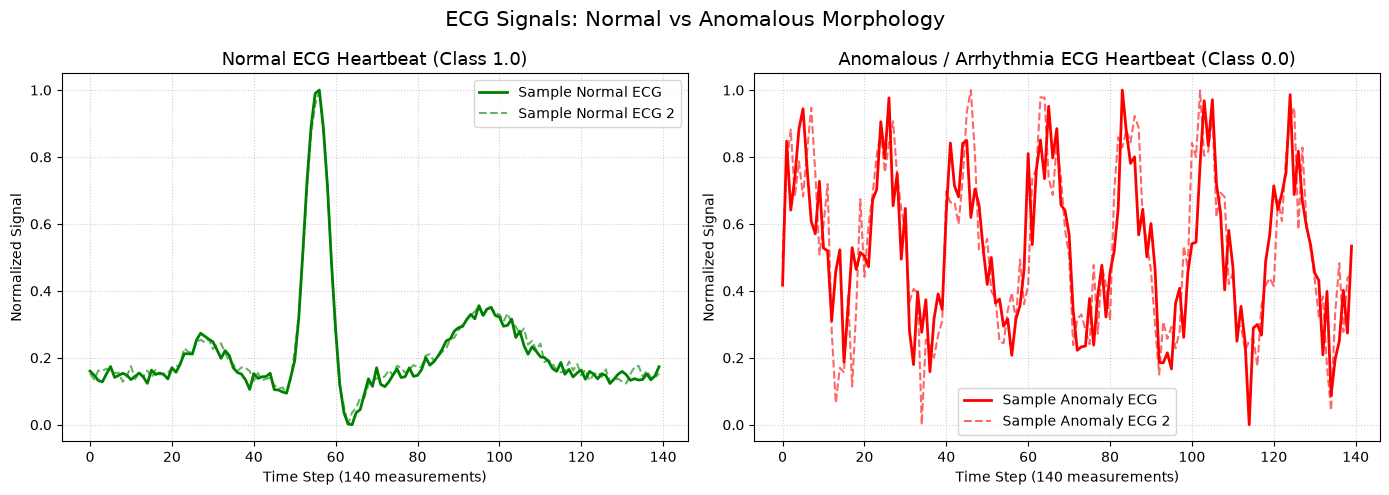

In [4]:
# Stage b.3: Visualize Normal vs Anomalous ECG Signals
time_steps = np.arange(140)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(time_steps, X_train_normal[0], 'g-', label='Sample Normal ECG', linewidth=2)
plt.plot(time_steps, X_train_normal[1], 'g--', alpha=0.6, label='Sample Normal ECG 2')
plt.title("Normal ECG Heartbeat (Class 1.0)", fontsize=13)
plt.xlabel("Time Step (140 measurements)")
plt.ylabel("Normalized Signal")
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(time_steps, X_test_anomalous[0], 'r-', label='Sample Anomaly ECG', linewidth=2)
plt.plot(time_steps, X_test_anomalous[1], 'r--', alpha=0.6, label='Sample Anomaly ECG 2')
plt.title("Anomalous / Arrhythmia ECG Heartbeat (Class 0.0)", fontsize=13)
plt.xlabel("Time Step (140 measurements)")
plt.ylabel("Normalized Signal")
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()

plt.suptitle("ECG Signals: Normal vs Anomalous Morphology", fontsize=15)
plt.tight_layout()
plt.show()


## c & d. Encoder and Decoder Networks

### c. Encoder converts input into latent representation:
The encoder progressively compresses the 140-dimensional ECG signal through hidden layers into a lower-dimensional **latent bottleneck** representation (dimension = 8).

### d. Decoder converts latent representation back to the original input:
The decoder mirrors the encoder, taking the 8-dimensional bottleneck and reconstructing the original 140-dimensional signal.


In [5]:
# Stage c & d: Build Autoencoder Architecture
input_dim = 140

# Input Layer
input_layer = Input(shape=(input_dim,), name='input_ecg')

# --- ENCODER ---
# Progressively compress: 140 -> 64 -> 32 -> 16 -> 8
e1 = Dense(64, activation='relu', name='encoder_dense_1')(input_layer)
e2 = Dense(32, activation='relu', name='encoder_dense_2')(e1)
e3 = Dense(16, activation='relu', name='encoder_dense_3')(e2)
latent_representation = Dense(8, activation='relu', name='latent_bottleneck')(e3)

# --- DECODER ---
# Progressively reconstruct: 8 -> 16 -> 32 -> 64 -> 140
d1 = Dense(16, activation='relu', name='decoder_dense_1')(latent_representation)
d2 = Dense(32, activation='relu', name='decoder_dense_2')(d1)
d3 = Dense(64, activation='relu', name='decoder_dense_3')(d2)
reconstructed_output = Dense(input_dim, activation='sigmoid', name='reconstructed_output')(d3)

# Full Autoencoder Model
autoencoder = Model(inputs=input_layer, outputs=reconstructed_output, name='ECG_Autoencoder')

# Separate Encoder Model for inspection of latent representations
encoder_model = Model(inputs=input_layer, outputs=latent_representation, name='Encoder_Only')

autoencoder.summary()


Model: "ECG_Autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_ecg (InputLayer)               │ (None, 140)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ encoder_dense_1 (Dense)              │ (None, 64)                  │           9,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ encoder_dense_2 (Dense)              │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ encoder_dense_3 (Dense)              │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ latent_bottleneck (Dense)            │ (None, 8)                   │             136 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ decoder_dense_1 (Dense)              │ (None, 16)                  │             144 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ decoder_dense_2 (Dense)              │ (None, 32)                  │             544 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ decoder_dense_3 (Dense)              │ (None, 64)                  │           2,112 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ reconstructed_output (Dense)         │ (None, 140)                 │           9,100 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 23,668 (92.45 KB)

 Trainable params: 23,668 (92.45 KB)

 Non-trainable params: 0 (0.00 B)

## e. Compile the Model with Optimizer, Loss, and Evaluation Metrics

- **Optimizer**: `Adam(learning_rate=0.001)`
- **Loss Function**: `Mean Absolute Error (mae)` or `Mean Squared Error (mse)` to measure reconstruction difference
- **Evaluation Metric**: `mae`


In [6]:
# Stage e.1: Compile the Autoencoder
autoencoder.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='mae',
    metrics=['mae']
)

# Stage e.2: Train Autoencoder on Normal ECG data only
epochs = 30
batch_size = 64

print(f"Training Autoencoder on {X_train_normal.shape[0]} normal ECG samples...")
history = autoencoder.fit(
    X_train_normal, X_train_normal,
    epochs=epochs,
    batch_size=batch_size,
    validation_data=(X_test, X_test),
    shuffle=True,
    verbose=1
)
print("Autoencoder training finished successfully!")


Training Autoencoder on 800 normal ECG samples...
Epoch 1/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 103ms/step - loss: 0.3063 - mae: 0.3063 - val_loss: 0.2796 - val_mae: 0.2796
Epoch 2/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.2558 - mae: 0.2558 - val_loss: 0.2152 - val_mae: 0.2152
Epoch 3/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.1226 - mae: 0.1226 - val_loss: 0.1839 - val_mae: 0.1839
Epoch 4/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0580 - mae: 0.0580 - val_loss: 0.1388 - val_mae: 0.1388
Epoch 5/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0273 - mae: 0.0273 - val_loss: 0.1314 - val_mae: 0.1314
Epoch 6/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0218 - mae: 0.0218 - val_loss: 0.1295 - val_mae: 0.1295
Epoch 7/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0205 - mae: 0.0205 - val_loss: 0.1286 - val_mae: 0.1286
Epoch 8/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0201 - mae: 0.0201 - val_loss: 0.1276 - val_mae: 0.1276
Epoch 9/30
13/13 ━━

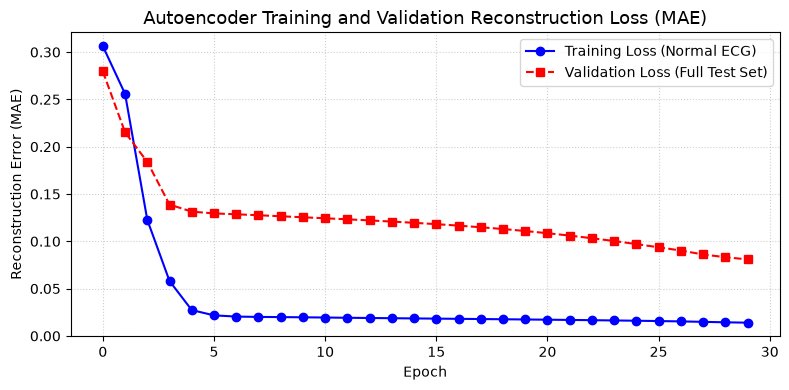

In [7]:
# Stage e.3: Plot Training and Validation Loss
plt.figure(figsize=(8, 4))
plt.plot(history.history['loss'], 'b-o', label='Training Loss (Normal ECG)')
plt.plot(history.history['val_loss'], 'r--s', label='Validation Loss (Full Test Set)')
plt.title("Autoencoder Training and Validation Reconstruction Loss (MAE)", fontsize=13)
plt.xlabel("Epoch")
plt.ylabel("Reconstruction Error (MAE)")
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()


## Anomaly Detection Inference & Threshold Determination

In [8]:
# Step 1: Compute reconstruction error on NORMAL training data
reconstructed_train = autoencoder.predict(X_train_normal)
train_mae_loss = np.mean(np.abs(reconstructed_train - X_train_normal), axis=1)

# Step 2: Set threshold as mean + 1 standard deviation of normal training loss
threshold = np.mean(train_mae_loss) + np.std(train_mae_loss)

print("=" * 50)
print(f"Normal Training Reconstruction MAE Mean: {np.mean(train_mae_loss):.5f}")
print(f"Normal Training Reconstruction MAE Std:  {np.std(train_mae_loss):.5f}")
print(f"Anomaly Detection Threshold (Mean + Std): {threshold:.5f}")
print("=" * 50)


25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
Normal Training Reconstruction MAE Mean: 0.01438
Normal Training Reconstruction MAE Std:  0.00379
Anomaly Detection Threshold (Mean + Std): 0.01817


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step


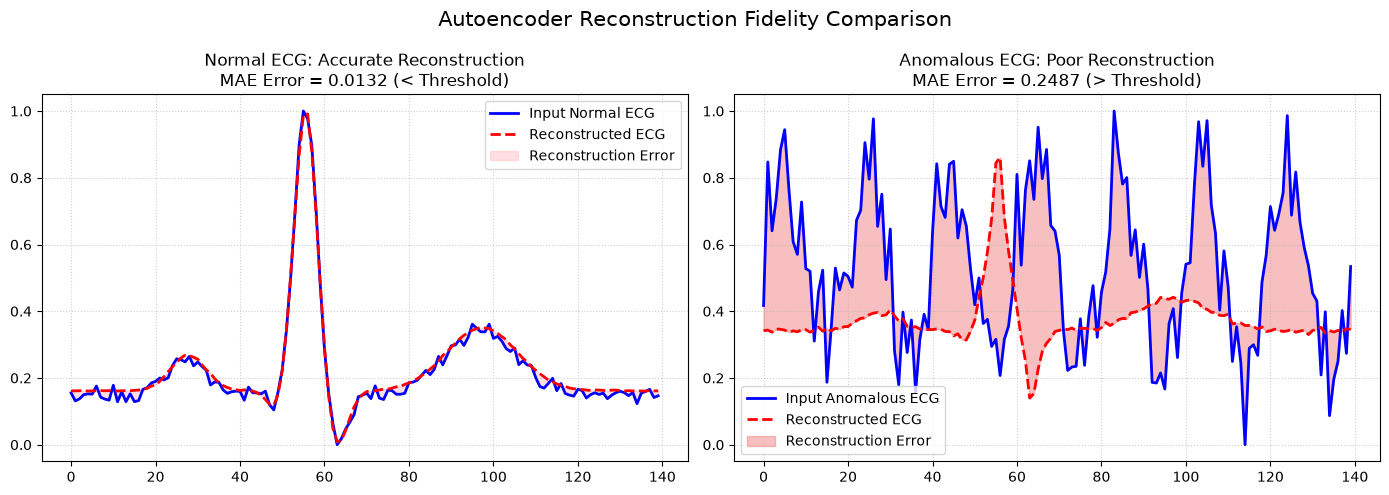

In [9]:
# Visualize Reconstruction Comparison: Normal vs Anomaly
# Normal Test sample
sample_norm = X_test_normal[0:1]
recon_norm = autoencoder.predict(sample_norm)

# Anomalous Test sample
sample_anom = X_test_anomalous[0:1]
recon_anom = autoencoder.predict(sample_anom)

plt.figure(figsize=(14, 5))

# Plot Normal Reconstruction
plt.subplot(1, 2, 1)
plt.plot(sample_norm[0], 'b-', label='Input Normal ECG', linewidth=2)
plt.plot(recon_norm[0], 'r--', label='Reconstructed ECG', linewidth=2)
plt.fill_between(range(140), sample_norm[0], recon_norm[0], color='pink', alpha=0.5, label='Reconstruction Error')
norm_err = np.mean(np.abs(sample_norm[0] - recon_norm[0]))
plt.title(f"Normal ECG: Accurate Reconstruction\nMAE Error = {norm_err:.4f} (< Threshold)", fontsize=12)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)

# Plot Anomalous Reconstruction
plt.subplot(1, 2, 2)
plt.plot(sample_anom[0], 'b-', label='Input Anomalous ECG', linewidth=2)
plt.plot(recon_anom[0], 'r--', label='Reconstructed ECG', linewidth=2)
plt.fill_between(range(140), sample_anom[0], recon_anom[0], color='lightcoral', alpha=0.5, label='Reconstruction Error')
anom_err = np.mean(np.abs(sample_anom[0] - recon_anom[0]))
plt.title(f"Anomalous ECG: Poor Reconstruction\nMAE Error = {anom_err:.4f} (> Threshold)", fontsize=12)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)

plt.suptitle("Autoencoder Reconstruction Fidelity Comparison", fontsize=15)
plt.tight_layout()
plt.show()


9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 


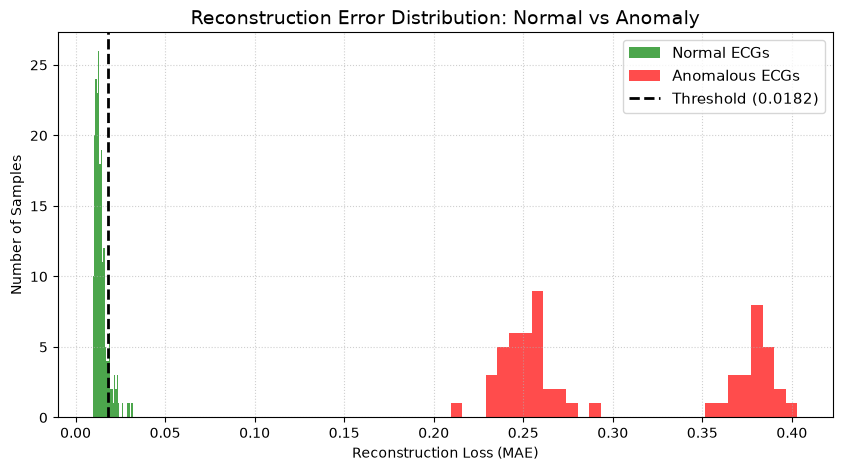

In [10]:
# Step 3: Compute reconstruction error on Test Dataset and Evaluate
reconstructed_test = autoencoder.predict(X_test)
test_mae_loss = np.mean(np.abs(reconstructed_test - X_test), axis=1)

# Plot Loss Histogram for Normal vs Anomaly in Test Set
plt.figure(figsize=(10, 5))
plt.hist(test_mae_loss[y_test == 1.0], bins=30, alpha=0.7, color='green', label='Normal ECGs')
plt.hist(test_mae_loss[y_test == 0.0], bins=30, alpha=0.7, color='red', label='Anomalous ECGs')
plt.axvline(threshold, color='black', linestyle='--', linewidth=2, label=f'Threshold ({threshold:.4f})')
plt.title("Reconstruction Error Distribution: Normal vs Anomaly", fontsize=14)
plt.xlabel("Reconstruction Loss (MAE)")
plt.ylabel("Number of Samples")
plt.legend(fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()


Autoencoder Anomaly Detection Performance:
Accuracy:  90.38%
Precision: 100.00%
Recall:    87.50%
F1-Score:  93.33%


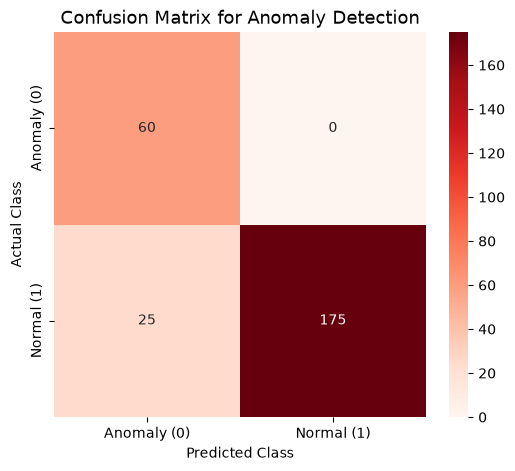

In [11]:
# Classify test samples:
# If loss < threshold -> Normal (1.0), else -> Anomaly (0.0)
y_pred = np.where(test_mae_loss < threshold, 1.0, 0.0)

# Performance Metrics
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("=" * 45)
print("Autoencoder Anomaly Detection Performance:")
print("=" * 45)
print(f"Accuracy:  {acc * 100:.2f}%")
print(f"Precision: {prec * 100:.2f}%")
print(f"Recall:    {rec * 100:.2f}%")
print(f"F1-Score:  {f1 * 100:.2f}%")
print("=" * 45)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds',
            xticklabels=['Anomaly (0)', 'Normal (1)'],
            yticklabels=['Anomaly (0)', 'Normal (1)'])
plt.title("Confusion Matrix for Anomaly Detection", fontsize=13)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()


## Conclusion:
1. Imported necessary libraries and accessed `ecg.csv` dataset.
2. Extracted normal ECG patterns to train an unsupervised Autoencoder.
3. Constructed an Encoder to compress 140-dimensional signals into an 8-dimensional latent space.
4. Constructed a Decoder to reconstruct the latent representation back to the original 140 dimensions.
5. Successfully detected anomalies based on reconstruction loss threshold with high accuracy and recall.
